# Finetuning LVH

Running `AS_detection/main.py` in this notebook.


## Setup

In [ ]:
# Hyperparameters (defaults match the argparse options in main.py)
data_dir = "data"
output_dir = "output"
clip_len = 16
sampling_rate = 1
num_clips = 4
model_name = "3dresnet18"
rand_init = False
n_gpu = 1
max_epochs = 10
patience = 1e4
lr = 1e-4
batch_size = 10
label_smoothing = 0.0
use_class_weights = False
dropout_fc = False
augment = False
lpft = ""
ssl = "ssl_pretraining/output/model-2026-1002"
frac = 1.0
weight_averaging = False
n_TTA = 0
seed = 0

In [ ]:
MODEL_NAME = model_name
MODEL_NAME += f"_frac-{frac}" if frac != 1.0 else ""
MODEL_NAME += "_pretr" if not rand_init else "_rand"
MODEL_NAME += f"_ssl-{ssl.split('/')[-1]}" if ssl != "" else ""
MODEL_NAME += "_aug" if augment else ""
MODEL_NAME += f"_clip-len-{clip_len}-stride-{sampling_rate}"
MODEL_NAME += f"_num-clips-{num_clips}"
MODEL_NAME += "_cw" if use_class_weights else ""
MODEL_NAME += f"_lr-{lr}"
MODEL_NAME += f"_{max_epochs}ep"
MODEL_NAME += f"_patience-{patience}" if patience != 1e4 else ""
MODEL_NAME += f"_bs-{batch_size}"
MODEL_NAME += f"_ls-{label_smoothing}" if label_smoothing != 0.0 else ""
MODEL_NAME += f"_drp-0.25" if dropout_fc else ""
MODEL_NAME += f"_weight-avg" if weight_averaging else ""
MODEL_NAME += f"_seed-{seed}" if seed != 0 else ""

MODEL_NAME += "_val-auc"

MODEL_NAME

In [ ]:
# Create output directory for model (and delete if already exists)
if not os.path.exists(output_dir):
    os.mkdir(output_dir)

model_dir = os.path.join(output_dir, MODEL_NAME)
if os.path.isdir(model_dir):
    shutil.rmtree(model_dir)
os.mkdir(model_dir)

model_dir

In [ ]:
# Set all seeds for reproducibility
set_seed(seed)

# Set device (main.py hardcodes cuda:0; fall back so this also runs on a Mac)
if torch.cuda.is_available():
    device = torch.device("cuda:0")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

device

## Create Model

In [ ]:
# Create model
if model_name == "3dresnet18":
    weights = torchvision.models.video.R3D_18_Weights.DEFAULT if not rand_init else None
    model = torchvision.models.video.r3d_18(weights=weights)

    if dropout_fc:
        model.fc = torch.nn.Sequential(  # type: ignore
            torch.nn.Linear(512, 1), torch.nn.Dropout(0.25)
        )

        if lpft != "":
            # Linear probing fine-tuning (LPFT) weights are stored in a dict under the key "weights"
            weights = dict(torch.load(lpft, map_location="cpu")["weights"])

            model.fc[0].weight.data = weights["fc.0.weight"]
            model.fc[0].bias.data = weights["fc.0.bias"]

    else:
        model.fc = torch.nn.Linear(512, 1)
        if lpft != "":
            # Linear probing fine-tuning (LPFT) weights are stored in a dict under the key "weights"
            weights = dict(torch.load(lpft, map_location="cpu")["weights"])

            model.fc.weight.data = weights["fc.weight"]
            model.fc.bias.data = weights["fc.bias"]

    if ssl != "":
        checkpoints = [f for f in os.listdir(ssl) if f.endswith(".pt")]
        idx = np.argmax([int(f.split(".")[0].split("-")[1]) for f in checkpoints])
        weights = torch.load(os.path.join(ssl, checkpoints[idx]), map_location="cpu")[
            "weights"
        ]
        weights = {
            k.replace("encoder.", ""): v for k, v in weights.items() if "encoder" in k
        }

        model.load_state_dict(weights, strict=False)


model = model.to(device)

## Create Dataset

### Train Dataset

In [ ]:
train_dataset = EchoDatasetLVHDetection(
    data_dir=data_dir,
    split="train",
    clip_len=clip_len,
    sampling_rate=sampling_rate,
    num_clips=num_clips,
    augment=augment,
    kinetics=(ssl == "") and (not rand_init),
)

In [ ]:
train_dataset[0]["x"]

In [ ]:
print(train_dataset.label_df.shape)
train_dataset.label_df.columns.tolist()

In [ ]:
print(train_dataset.label_df.head())
print(train_dataset.video_dir)
print(os.listdir(train_dataset.video_dir)[:5])

### Val Dataset

In [ ]:
val_dataset = EchoDatasetLVHDetection(
    data_dir=data_dir,
    split="val",
    clip_len=clip_len,
    sampling_rate=sampling_rate,
    num_clips=num_clips,
    kinetics=(ssl == "") and (not rand_init),
)

### Test Dataset

In [ ]:
test_dataset = EchoDatasetLVHDetection(
    data_dir=data_dir,
    split="test",
    clip_len=clip_len,
    sampling_rate=sampling_rate,
    num_clips=num_clips,
    kinetics=(ssl == "") and (not rand_init),
)

## Create DataLoader

### Train DataLoader

In [ ]:
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=n_gpu * batch_size,
    shuffle=True,
    num_workers=8,
    worker_init_fn=seed_worker,
)

### Val DataLoader

In [ ]:
val_loader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=n_gpu * batch_size,
    shuffle=False,
    num_workers=8,
)

### Train Loader

In [ ]:
test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=n_gpu * batch_size,
    shuffle=False,
    num_workers=8,
)

## Initialize Model Training Loop

In [ ]:
# Create csv documenting training history
history = pd.DataFrame(
    columns=[
        "epoch",
        "phase",
        "loss",
        "auroc",
        "aupr",
        "acc",
        "b_acc",
        "mcc",
        "precision",
        "recall",
        "f1",
    ]
)
# history.to_csv(os.path.join(model_dir, "history.csv"), index=False)

if use_class_weights:
    class_weights = compute_class_weight(
        class_weight="balanced",
        classes=np.sort(
            np.unique((train_dataset.label_df["av_stenosis"] == "Severe").values)
        ),
        y=(train_dataset.label_df["av_stenosis"] == "Severe").values,
    )

    print("Class weights:", class_weights)

    pos_weight = (class_weights / class_weights.min())[1]

    print("Normalized positive class weight:", pos_weight)

    loss_fxn = torch.nn.BCEWithLogitsLoss(
        pos_weight=torch.Tensor([pos_weight]).to(device)
    )
    eval_loss_fxn = torch.nn.BCELoss(weight=torch.Tensor([pos_weight]).to(device))
else:
    loss_fxn = torch.nn.BCEWithLogitsLoss()
    eval_loss_fxn = torch.nn.BCELoss()

# Create optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

## Train Model

In [ ]:
data_loader = train_loader
epoch = 1

In [ ]:
# model.train()

# pbar = tqdm.tqdm(enumerate(data_loader), total=len(data_loader), desc=f"Epoch {epoch}")
# running_loss = 0.0
# y_true, y_hat = [], []
# acc_nums = []
# plax_probs = []

In [ ]:
train_dataset[0]["x"].shape

In [ ]:
# for i, batch in pbar:
#         x, y = batch['x'].to(device), batch['y'].to(device)
#         print("Batch", i)
#         print("x shape:", x.shape)
#         print("y shape:", y.shape)

#         print("Acc num:", batch['acc_num'])

In [ ]:
model.train()

pbar = tqdm.tqdm(enumerate(data_loader), total=len(data_loader), desc=f"Epoch {epoch}")
running_loss = 0.0
y_true, y_hat = [], []
acc_nums = []
plax_probs = []

for i, batch in pbar:
    x, y = batch["x"].to(device), batch["y"].to(device)
    acc_num = batch["acc_num"]

    # Forward pass
    out = model(x)

    # Compute loss
    loss = loss_fxn(out, y)

    # Backward pass
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    # Keep running sum of batch losses
    running_loss += loss.item()

    y_true.append(y.detach().cpu().numpy())
    y_hat.append(out.sigmoid().detach().cpu().numpy())
    acc_nums.append(acc_num)

    del out
    del loss

    pbar.set_postfix({"loss": running_loss / (i + 1)})  # , 'b_acc': balanced_acc})


In [ ]:
video_label_df = pd.DataFrame(
    {
        "y_true": np.concatenate(y_true).ravel(),
        "y_hat": np.concatenate(y_hat).ravel(),
        "acc_num": np.concatenate(acc_nums).ravel(),
    }
)

study_label_df = video_label_df.groupby(by=["acc_num"]).agg(
    {"y_true": np.mean, "y_hat": np.mean}
)

y_true = video_label_df["y_true"]
y_hat = video_label_df["y_hat"]

# AUROC
auroc = metrics.roc_auc_score(y_true, y_hat)
pr, re, _ = metrics.precision_recall_curve(y_true, y_hat)
aupr = metrics.auc(re, pr)

# Other metrics
acc = metrics.accuracy_score(y_true, y_hat.round())
b_acc = metrics.balanced_accuracy_score(y_true, y_hat.round())
mcc = metrics.matthews_corrcoef(y_true, y_hat.round())
pr, re, f1, _ = metrics.precision_recall_fscore_support(
    y_true, y_hat.round(), average="binary"
)

out_str = f"[VIDEO LEVEL]   AUROC: {auroc:.3f} | AUPR: {aupr:.3f} | Acc: {acc:.3f} | BAcc: {b_acc:.3f} | MCC: {mcc:.3f} | Precision: {pr:.3f} | Recall: {re:.3f} | F1: {f1:.3f}"
print(out_str)

# Append metrics to history df
current_metrics = pd.DataFrame(
    [
        [
            epoch,
            "train",
            running_loss / (i + 1),
            auroc,
            aupr,
            acc,
            b_acc,
            mcc,
            pr,
            re,
            f1,
        ]
    ],
    columns=history.columns,
)
# current_metrics.to_csv(
#     os.path.join(model_dir, "history.csv"), mode="a", header=False, index=False
# )

## Validate Model

In [ ]:
model.eval()

pbar = tqdm.tqdm(
    enumerate(data_loader), total=len(data_loader), desc=f"[VAL] Epoch {epoch}"
)
running_loss = 0.0
y_true, y_hat = [], []
acc_nums = []
plax_probs = []
with torch.no_grad():
    for i, batch in pbar:
        x, y = batch["x"].to(device), batch["y"].to(device)
        acc_num = batch["acc_num"]

        # Forward pass
        out = torch.stack(
            [model(x[:, :, clip, :, :, :]) for clip in range(x.shape[2])], dim=0
        )

        # Get softmax probabilities and video-wise average over clip dimension
        out = out.sigmoid().mean(dim=0)

        # Compute loss
        loss = loss_fxn(out, y)

        # Keep running sum of batch losses
        running_loss += loss.item()

        y_true.append(y.detach().cpu().numpy())
        y_hat.append(out.detach().cpu().numpy())
        acc_nums.append(acc_num)

        del out
        del loss

        pbar.set_postfix({"loss": running_loss / (i + 1)})  # , 'b_acc': balanced_acc})


In [ ]:
video_label_df = pd.DataFrame(
    {
        "y_true": np.concatenate(y_true).ravel(),
        "y_hat": np.concatenate(y_hat).ravel(),
        "acc_num": np.concatenate(acc_nums).ravel(),
    }
)

y_true = video_label_df["y_true"]
y_hat = video_label_df["y_hat"]

# AUROC
auroc = metrics.roc_auc_score(y_true, y_hat)
pr, re, _ = metrics.precision_recall_curve(y_true, y_hat)
aupr = metrics.auc(re, pr)

# Other metrics
acc = metrics.accuracy_score(y_true, y_hat.round())
b_acc = metrics.balanced_accuracy_score(y_true, y_hat.round())
mcc = metrics.matthews_corrcoef(y_true, y_hat.round())
pr, re, f1, _ = metrics.precision_recall_fscore_support(
    y_true, y_hat.round(), average="binary"
)

out_str = f"[VIDEO LEVEL]   AUROC: {auroc:.3f} | AUPR: {aupr:.3f} | Acc: {acc:.3f} | BAcc: {b_acc:.3f} | MCC: {mcc:.3f} | Precision: {pr:.3f} | Recall: {re:.3f} | F1: {f1:.3f}"
print(out_str)

In [ ]:
# Append metrics to history df
val_loss = running_loss / (i + 1)

current_metrics = pd.DataFrame(
    [
        [
            epoch,
            "val",
            running_loss / (i + 1),
            auroc,
            aupr,
            acc,
            b_acc,
            mcc,
            pr,
            re,
            f1,
        ]
    ],
    columns=history.columns,
)
current_metrics.to_csv(
    os.path.join(model_dir, "history.csv"), mode="a", header=False, index=False
)

# Early stopping: save model weights only when val AUC has improved
if auroc > early_stopping_dict["best_auroc"]:
    print(
        f"EARLY STOPPING: AUROC has improved from {round(early_stopping_dict['best_auroc'], 3)} to {round(auroc, 3)}! Saving weights."
    )
    early_stopping_dict["epochs_no_improve"] = 0
    early_stopping_dict["best_auroc"] = auroc
    best_model_wts = (
        deepcopy(model.state_dict())
        if not isinstance(model, torch.nn.DataParallel)
        else deepcopy(model.module.state_dict())
    )
    torch.save(
        {"weights": best_model_wts, "optimizer": optimizer.state_dict()},
        os.path.join(model_dir, f"chkpt_epoch-{epoch}.pt"),
    )
else:
    print(
        f"EARLY STOPPING: AUROC has not improved from {round(early_stopping_dict['best_auroc'], 3)}"
    )
    early_stopping_dict["epochs_no_improve"] += 1

return history.append(current_metrics), early_stopping_dict, best_model_wts


## Evaluate Model

## (Main) LVH Detection

Running `LVH_detection/main.py`

In [13]:
import os
import shutil
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torchvision
import tqdm
from sklearn import metrics

LVH_DIR = Path.cwd() / "LVH_detection"
sys.path.insert(0, str(LVH_DIR))

from dataset import EchoDatasetLVHDetection
from utils import evaluate, seed_worker, set_seed, train, validate

In [2]:
# Hyperparameters (defaults match the argparse options in main.py)
data_dir = "data"
output_dir = "output"
clip_len = 16
sampling_rate = 1
num_clips = 4
model_name = "3dresnet18"
rand_init = False
n_gpu = 1
max_epochs = 10
patience = 1e4
lr = 1e-4
batch_size = 10
label_smoothing = 0.0
use_class_weights = False
dropout_fc = False
augment = False
lpft = ""
ssl = "ssl_pretraining/output/model-2026-1002"
frac = 1.0
weight_averaging = False
n_TTA = 0
seed = 0

In [3]:
MODEL_NAME = model_name
MODEL_NAME += f"_frac-{frac}" if frac != 1.0 else ""
MODEL_NAME += "_pretr" if not rand_init else "_rand"
MODEL_NAME += f"_ssl-{ssl.split('/')[-1]}" if ssl != "" else ""
MODEL_NAME += "_aug" if augment else ""
MODEL_NAME += f"_clip-len-{clip_len}-stride-{sampling_rate}"
MODEL_NAME += f"_num-clips-{num_clips}"
MODEL_NAME += "_cw" if use_class_weights else ""
MODEL_NAME += f"_lr-{lr}"
MODEL_NAME += f"_{max_epochs}ep"
MODEL_NAME += f"_patience-{patience}" if patience != 1e4 else ""
MODEL_NAME += f"_bs-{batch_size}"
MODEL_NAME += f"_ls-{label_smoothing}" if label_smoothing != 0.0 else ""
MODEL_NAME += f"_drp-0.25" if dropout_fc else ""
MODEL_NAME += f"_weight-avg" if weight_averaging else ""
MODEL_NAME += f"_seed-{seed}" if seed != 0 else ""

MODEL_NAME += "_val-auc"

MODEL_NAME

'3dresnet18_pretr_ssl-model-2026-1002_clip-len-16-stride-1_num-clips-4_lr-0.0001_10ep_bs-10_val-auc'

In [5]:
# Create output directory for model (and delete if already exists)
if not os.path.exists(output_dir):
    os.mkdir(output_dir)

model_dir = os.path.join(output_dir, MODEL_NAME)
if os.path.isdir(model_dir):
    shutil.rmtree(model_dir)
os.mkdir(model_dir)

model_dir

'output/3dresnet18_pretr_ssl-model-2026-1002_clip-len-16-stride-1_num-clips-4_lr-0.0001_10ep_bs-10_val-auc'

In [4]:
# Set all seeds for reproducibility
set_seed(seed)

# Set device (main.py hardcodes cuda:0; fall back so this also runs on a Mac)
if torch.cuda.is_available():
    device = torch.device("cuda:0")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

device

device(type='mps')

In [6]:
# Create model
if model_name == "3dresnet18":
    weights = torchvision.models.video.R3D_18_Weights.DEFAULT if not rand_init else None
    model = torchvision.models.video.r3d_18(weights=weights)

    if dropout_fc:
        model.fc = torch.nn.Sequential(  # type: ignore
            torch.nn.Linear(512, 1), torch.nn.Dropout(0.25)
        )

        if lpft != "":
            # Linear probing fine-tuning (LPFT) weights are stored in a dict under the key "weights"
            weights = dict(torch.load(lpft, map_location="cpu")["weights"])

            model.fc[0].weight.data = weights["fc.0.weight"]
            model.fc[0].bias.data = weights["fc.0.bias"]

    else:
        model.fc = torch.nn.Linear(512, 1)
        if lpft != "":
            # Linear probing fine-tuning (LPFT) weights are stored in a dict under the key "weights"
            weights = dict(torch.load(lpft, map_location="cpu")["weights"])

            model.fc.weight.data = weights["fc.weight"]
            model.fc.bias.data = weights["fc.bias"]

    if ssl != "":
        checkpoints = [f for f in os.listdir(ssl) if f.endswith(".pt")]
        idx = np.argmax([int(f.split(".")[0].split("-")[1]) for f in checkpoints])
        weights = torch.load(os.path.join(ssl, checkpoints[idx]), map_location="cpu")[
            "weights"
        ]
        weights = {
            k.replace("encoder.", ""): v for k, v in weights.items() if "encoder" in k
        }

        model.load_state_dict(weights, strict=False)


model = model.to(device)

In [7]:
train_dataset = EchoDatasetLVHDetection(
    data_dir=data_dir,
    split="train",
    clip_len=clip_len,
    sampling_rate=sampling_rate,
    num_clips=num_clips,
    augment=augment,
    kinetics=(ssl == "") and (not rand_init),
)

val_dataset = EchoDatasetLVHDetection(
    data_dir=data_dir,
    split="val",
    clip_len=clip_len,
    sampling_rate=sampling_rate,
    num_clips=num_clips,
    kinetics=(ssl == "") and (not rand_init),
)

test_dataset = EchoDatasetLVHDetection(
    data_dir=data_dir,
    split="test",
    clip_len=clip_len,
    sampling_rate=sampling_rate,
    num_clips=num_clips,
    kinetics=(ssl == "") and (not rand_init),
)

LVH class distribution (train split):
lvh
0    0.8
1    0.2
Name: proportion, dtype: float64
LVH class distribution (val split):
lvh
0    0.8
1    0.2
Name: proportion, dtype: float64
LVH class distribution (test split):
lvh
0    0.5
1    0.5
Name: proportion, dtype: float64


In [8]:
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=n_gpu * batch_size,
    shuffle=True,
    num_workers=8,
    worker_init_fn=seed_worker,
)

val_loader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=n_gpu * batch_size,
    shuffle=False,
    num_workers=8,
    worker_init_fn=seed_worker,
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=n_gpu * batch_size,
    shuffle=False,
    num_workers=8,
)

In [9]:
# Create csv documenting training history
history = pd.DataFrame(
    columns=[
        "epoch",
        "phase",
        "loss",
        "auroc",
        "aupr",
        "acc",
        "b_acc",
        "mcc",
        "precision",
        "recall",
        "f1",
    ]
)
history.to_csv(os.path.join(model_dir, "history.csv"), index=False)

In [10]:
loss_fxn = torch.nn.BCEWithLogitsLoss()
eval_loss_fxn = torch.nn.BCELoss()

In [11]:
# Create optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

# Train with early stopping
epoch = 1
early_stopping_dict = {"best_auroc": 0.0, "epochs_no_improve": 0}
best_model_wts = None

In [14]:
while (
        epoch <= max_epochs
        and early_stopping_dict["epochs_no_improve"] < patience
    ):
        history = train(
            model=model,
            device=device,
            loss_fxn=loss_fxn,
            optimizer=optimizer,
            data_loader=train_loader,
            history=history,
            epoch=epoch,
            model_dir=model_dir,
        )
        history, early_stopping_dict, best_model_wts = validate(
            model=model,
            device=device,
            loss_fxn=eval_loss_fxn,
            optimizer=optimizer,
            data_loader=val_loader,
            history=history,
            epoch=epoch,
            model_dir=model_dir,
            early_stopping_dict=early_stopping_dict,
            best_model_wts=best_model_wts,
        )

        epoch += 1

Epoch 1: 100%|██████████| 1/1 [00:28<00:00, 28.29s/it, loss=0.764]

[VIDEO LEVEL]   AUROC: 0.688 | AUPR: 0.258 | Acc: 0.200 | BAcc: 0.500 | MCC: 0.000 | Precision: 0.200 | Recall: 1.000 | F1: 0.333



[VAL] Epoch 1: 100%|██████████| 1/1 [00:15<00:00, 15.81s/it, loss=1.33]


[VIDEO LEVEL]   AUROC: 0.500 | AUPR: 0.167 | Acc: 0.200 | BAcc: 0.500 | MCC: 0.000 | Precision: 0.200 | Recall: 1.000 | F1: 0.333
EARLY STOPPING: AUROC has improved from 0.0 to 0.5! Saving weights.


Epoch 2: 100%|██████████| 1/1 [00:24<00:00, 24.62s/it, loss=0.698]

...

[VIDEO LEVEL]   AUROC: 0.750 | AUPR: 0.250 | Acc: 0.600 | BAcc: 0.750 | MCC: 0.408 | Precision: 0.333 | Recall: 1.000 | F1: 0.500
EARLY STOPPING: AUROC has not improved from 0.75



Epoch 10: 100%|██████████| 1/1 [00:24<00:00, 24.72s/it, loss=0.358]

[VIDEO LEVEL]   AUROC: 0.938 | AUPR: 0.792 | Acc: 0.900 | BAcc: 0.750 | MCC: 0.667 | Precision: 1.000 | Recall: 0.500 | F1: 0.667



[VAL] Epoch 10: 100%|██████████| 1/1 [00:14<00:00, 14.63s/it, loss=0.537]


[VIDEO LEVEL]   AUROC: 0.750 | AUPR: 0.250 | Acc: 0.800 | BAcc: 0.875 | MCC: 0.612 | Precision: 0.500 | Recall: 1.000 | F1: 0.667
EARLY STOPPING: AUROC has not improved from 0.75


[TEST] EVALUATION: 100%|██████████| 1/1 [00:17<00:00, 17.30s/it, loss=0.921]
/Users/howardbaek/Documents/echo-severe-as/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/howardbaek/Documents/echo-severe-as/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/howardbaek/Documents/echo-severe-as/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with n

test
   y_true     y_hat             acc_num
0     0.0  0.748009  0X967F41BAF9502275
1     1.0  0.754438  0X998AABD56D7845A3
2     1.0  0.721971  0X4445C05B3D5E446A
3     0.0  0.816992  0X587725088015574A
[VIDEO LEVEL]   AUROC: 0.250 | AUPR: 0.333 | Acc: 0.500 | BAcc: 0.500 | MCC: 0.000 | Precision: 0.500 | Recall: 1.000 | F1: 0.667
              precision    recall  f1-score   support

        None      0.000     0.000     0.000         2
         LVH      0.500     1.000     0.667         2

    accuracy                          0.500         4
   macro avg      0.250     0.500     0.333         4
weighted avg      0.250     0.500     0.333         4



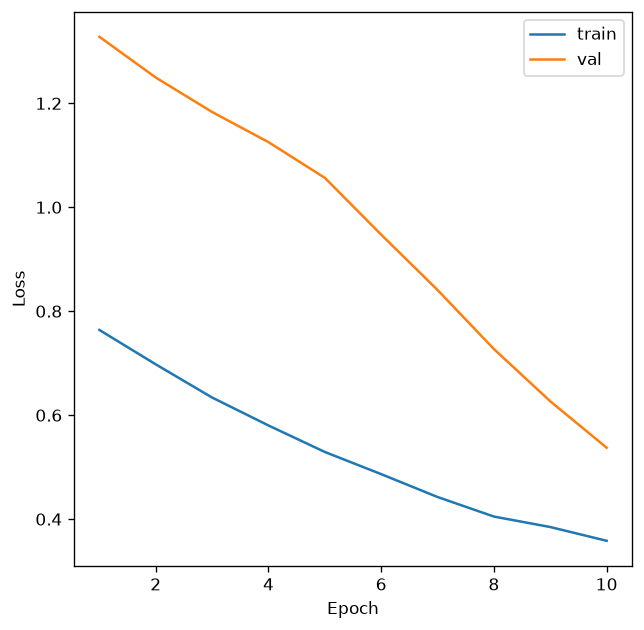

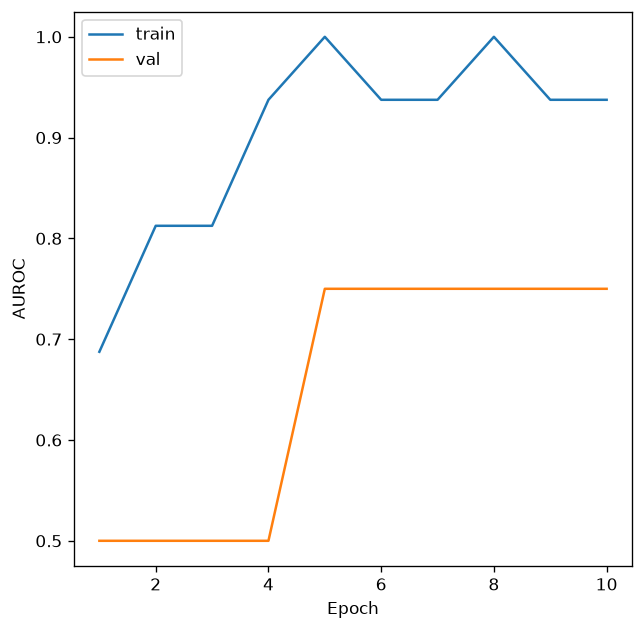

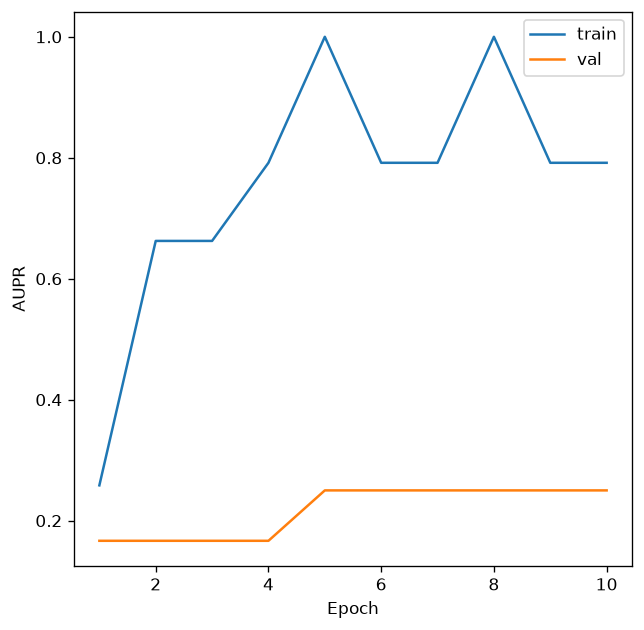

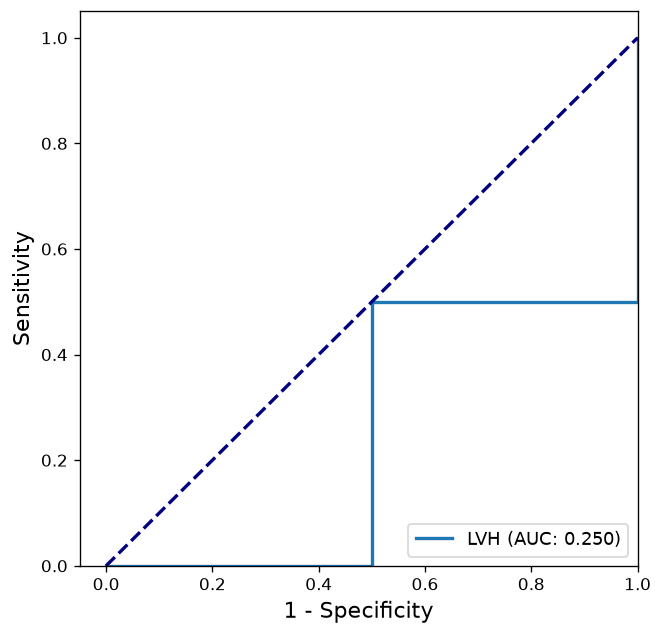

In [15]:
# # Evaluate on test set
evaluate(
    model=model,
    device=device,
    loss_fxn=eval_loss_fxn,
    data_loader=test_loader,
    split="test",
    classes=test_dataset.CLASSES,
    history=history,
    model_dir=model_dir,
    weights=best_model_wts,
)
